# Week 6 experimental: feasibility of 19 ICD-string multilabel targets

**Scope.** Descriptive audit of the existing patient-level **training and validation** partitions only. This notebook creates no models and reads no ECG waveforms. It reads held-out **patient IDs only** to reconstruct the historical split; held-out `ICD-10 code`, age, lead configuration, and waveforms are not inspected. In particular, test-class distributions are unknown.

**Question.** Are the 19 exact disease-code strings in `Data/DiseaseCode.csv` sufficiently distinct, reliable, and represented to support 19 separate ECG prediction targets? A selected code is matched only as a complete semicolon-separated token in `AttributesDictionary.csv`/`ICD-10 code`. `AHA_code` and `CHN_code` are ECG statements, never disease targets.

**Prior pipeline.** `new work/Week5/experimental/Architecture_Comparison.ipynb` uses sorted patient IDs, seed 42, 70/15/15, with floor rounding; this notebook reproduces that split. The binary target used there is the union of the 19 selected tokens. All outputs here are aggregate tables only; patient identifiers remain in memory. No binary notebook, checkpoint, split, or result is modified.

**Sources.** Local dataset descriptor: `Docs/ECG_Paper1.pdf` (Tan et al., *Scientific Data*, 2025, DOI 10.1038/s41597-025-05225-z), especially acquisition/label methods and Usage Notes. The authors say inpatient diagnoses from medical records were linked to ECGs by patient and hospitalization period; the disease codes were converted under clinical/coding guidance. This does not provide independent ECG-time disease adjudication. The codebook contains local qualifiers on shared ICD bases; see the NHS ICD-10 tabular definitions [I40/I37](https://classbrowser.nhs.uk/ICD-10-5TH-Edition/vol1/block-i30-i52.htm) and [Q21/Q22/Q24](https://classbrowser.nhs.uk/ICD-10-5TH-Edition/vol1/block-q20-q28.htm).

In [1]:
from pathlib import Path
import csv, random, re, itertools
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'Data/AttributesDictionary.csv').exists():
    if ROOT==ROOT.parent: raise FileNotFoundError('Run within the project tree')
    ROOT=ROOT.parent
OUT=ROOT/'new work/Week6/experimental/multilabel_feasibility'
SEED=42
META=ROOT/'Data/AttributesDictionary.csv'
BOOK=ROOT/'Data/DiseaseCode.csv'
assert OUT.exists()
print('Project:',ROOT)
print('Output:',OUT)

Project: /home/souhit/Documents/Research/Pediatric_ECG
Output: /home/souhit/Documents/Research/Pediatric_ECG/new work/Week6/experimental/multilabel_feasibility


## Patient split and label vocabulary

The first pass extracts only `Patient_ID` and record counts from the metadata. No diagnosis field is indexed for held-out patients. The second pass skips held-out patients **before** indexing any diagnosis or demographic fields.

In [2]:
with META.open(newline='') as f:
    reader=csv.reader(f)
    header=next(reader)
    patient_index=header.index('Patient_ID')
    id_counts=Counter(row[patient_index] for row in reader)
patient_ids=sorted(id_counts)
random.Random(SEED).shuffle(patient_ids)
n_train=int(.70*len(patient_ids)); n_val=int(.15*len(patient_ids))
train_ids=set(patient_ids[:n_train]); val_ids=set(patient_ids[n_train:n_train+n_val]); heldout_ids=set(patient_ids[n_train+n_val:])
assert not (train_ids&val_ids or train_ids&heldout_ids or val_ids&heldout_ids)
codebook=pd.read_csv(BOOK,keep_default_na=False)
selected_book=codebook.loc[codebook['Disease Type']!='Other diseases(OD)'].copy()
selected_book['code']=selected_book['ICD-10 Code'].str.strip()
selected_codes=selected_book.code.tolist()
selected_set=set(selected_codes)
assert len(selected_codes)==len(selected_set)==19
assert len(patient_ids)==11643 and len(train_ids)==8150 and len(val_ids)==1746 and len(heldout_ids)==1747
print('Patient counts:',len(train_ids),len(val_ids),len(heldout_ids),'(train, validation, held-out IDs only)')
print('Record counts from IDs:',sum(id_counts[p] for p in train_ids),sum(id_counts[p] for p in val_ids),sum(id_counts[p] for p in heldout_ids))
display(selected_book[['Disease Category','code']].reset_index(drop=True))

Patient counts: 8150 1746 1747 (train, validation, held-out IDs only)
Record counts from IDs: 9943 2169 2078


,Disease Category,code
0,Fulminant myocarditis,(F) I40.0
1,Viral myocarditis,(V) I40.0
2,Acute myocarditis,I40.9
3,Myocarditis,I51.4
4,Dilated cardiomyopathy,I42.0
5,Hypertrophic cardiomyopathy,I42.2
6,Cardiomyopathy,I42.9
7,Noncompaction of the ventricular myocardium,Q24.8
8,Kawasaki disease,M30.3
9,Ventricular septal defect,Q21.0


In [3]:
def icd_tokens(value):
    return [part.strip().strip("'\"").strip() for part in value.split(';') if part.strip()]
rows=[]
with META.open(newline='') as f:
    for row in csv.DictReader(f):
        pid=row['Patient_ID']
        if pid in heldout_ids:
            continue  # no held-out diagnosis, age, lead, or signal field is accessed
        assert pid in train_ids or pid in val_ids
        raw_icd=row['ICD-10 code']
        toks=icd_tokens(raw_icd)
        assert re.fullmatch(r'\d+d',row['Age'])
        rows.append({'split':'train' if pid in train_ids else 'validation',
                     'patient_id':pid,'ecg_id':row['ECG_ID'],'filename':row['Filename'],
                     'acquisition_date':row['Acquisition_date'],'age_days':int(row['Age'][:-1]),
                     'lead_count':int(row['Lead']),'raw_icd':raw_icd,
                     'aha_code':row['AHA_code'], 'tokens':toks,
                     'selected':frozenset(set(toks)&selected_set),
                     'duplicate_token_count':len(toks)-len(set(toks))})
D=pd.DataFrame(rows)
D['n_selected']=D.selected.map(len)
D['n_icd_tokens']=D.tokens.map(len)
D['age_years']=D.age_days/365.25
D['age_group']=pd.cut(D.age_years,[-np.inf,2,6,12,np.inf],labels=['<2','2–<6','6–<12','≥12'],right=False)
assert len(D)==12112 and D.ecg_id.is_unique and D.filename.is_unique
assert D.age_group.notna().all() and set(D.lead_count)=={9,12}
assert (D.groupby('split').size().to_dict()=={'train':9943,'validation':2169})
assert (D.groupby('split').n_selected.apply(lambda s:(s>0).sum()).to_dict()=={'train':2595,'validation':583})
print('Loaded train+validation rows:',len(D),'— held-out rows excluded before diagnosis access')

Loaded train+validation rows: 12112 — held-out rows excluded before diagnosis access


## Availability and meaning of a missing or absent code

A populated `ICD-10 code` field establishes that a string is supplied. It does **not** establish that every possible diagnosis has been captured, that a code was active at ECG time, or that absence is a clinically verified negative. We separate blank fields from records with other ICD tokens but no selected code.

In [4]:
audit=[]
for split,g in D.groupby('split',sort=False):
    audit.append({'split':split,'records':len(g),'patients':g.patient_id.nunique(),
                  'blank_icd_field':int(g.raw_icd.map(lambda x:not x.strip()).sum()),
                  'no_parsed_tokens':int((g.n_icd_tokens==0).sum()),
                  'duplicate_token_records':int((g.duplicate_token_count>0).sum()),
                  'selected_positive_records':int((g.n_selected>0).sum()),
                  'other_icd_only_records':int(((g.n_selected==0)&(g.n_icd_tokens>0)).sum()),
                  'distinct_icd_tokens':len(set(itertools.chain.from_iterable(g.tokens)))})
source_audit=pd.DataFrame(audit)
source_audit.to_csv(OUT/'source_field_audit.csv',index=False)
display(source_audit)
print('Any tokens across train+validation:',len(set(itertools.chain.from_iterable(D.tokens))))
print('Unqualified I40.0 token occurrences:',sum('I40.0' in ts for ts in D.tokens))
print('Age missing:',D.age_days.isna().sum(),'Lead counts:',D.lead_count.value_counts().to_dict())

,split,records,patients,blank_icd_field,no_parsed_tokens,duplicate_token_records,selected_positive_records,other_icd_only_records,distinct_icd_tokens
0,train,9943,8150,0,0,0,2595,7348,2007
1,validation,2169,1746,0,0,0,583,1586,1112


Any tokens across train+validation: 2177
Unqualified I40.0 token occurrences: 0
Age missing: 0 Lead counts: {12: 10533, 9: 1579}


In [5]:
repeat=D.groupby('patient_id',sort=False).agg(records=('ecg_id','size'),unique_dates=('acquisition_date','nunique'),
    unique_ages=('age_days','nunique'),unique_icd_strings=('raw_icd','nunique'),
    unique_aha_strings=('aha_code','nunique'),unique_lead_counts=('lead_count','nunique'))
rep=repeat[repeat.records>=2]
repeat_audit=pd.DataFrame([{'repeated_patients':len(rep),
    'with_multiple_acquisition_dates':int((rep.unique_dates>1).sum()),
    'with_multiple_ages':int((rep.unique_ages>1).sum()),
    'with_multiple_icd_strings':int((rep.unique_icd_strings>1).sum()),
    'with_multiple_aha_strings':int((rep.unique_aha_strings>1).sum()),
    'with_multiple_lead_counts':int((rep.unique_lead_counts>1).sum())}])
repeat_audit.to_csv(OUT/'repeat_patient_audit.csv',index=False)
display(repeat_audit)
assert (rep.unique_icd_strings==1).all()

,repeated_patients,with_multiple_acquisition_dates,with_multiple_ages,with_multiple_icd_strings,with_multiple_aha_strings,with_multiple_lead_counts
0,1448,1448,1260,0,1247,181


**Interpretation.** Identical ICD strings on repeated ECGs, including different dates and ages, are observed. The dataset paper describes diagnoses originating in inpatient medical records, matched to ECGs by patient and hospitalization dates. This pattern is consistent with patient or admission diagnoses being carried across records; it does not prove the exact linkage rule. The record-level target is therefore “ECG linked to an annotated diagnosis,” not an independently adjudicated contemporaneous disease state.

## Selected-label frequency and patient denominators

Counts are **not mutually exclusive**. Patient counts use unique patient IDs within each split. Prevalence denominators are all records/patients in that split; repeated ECGs can inflate record counts.

In [6]:
book_lookup=selected_book.set_index('code')
code_rows=[]
for split,g in D.groupby('split',sort=False):
    n_records=len(g); n_patients=g.patient_id.nunique()
    for code in selected_codes:
        sub=g.loc[g.selected.map(lambda ss:code in ss).to_numpy(dtype=bool)]
        code_rows.append({'split':split,'code':code,'category':book_lookup.loc[code,'Disease Category'],
            'records':len(sub),'patients':sub.patient_id.nunique(),
            'record_prevalence':len(sub)/n_records,'patient_prevalence':sub.patient_id.nunique()/n_patients,
            'nine_lead_records':int((sub.lead_count==9).sum()),'twelve_lead_records':int((sub.lead_count==12).sum()),
            'median_age_years':sub.age_years.median() if len(sub) else np.nan})
per_code=pd.DataFrame(code_rows)
per_code.to_csv(OUT/'per_code_by_split.csv',index=False)
display(per_code.pivot(index='code',columns='split',values=['records','patients']).reindex(selected_codes).astype(int))
print('Labels absent from validation:',per_code.query("split=='validation' and records==0").code.tolist())
print('Labels with <10 validation patients:',per_code.query("split=='validation' and patients<10")[['code','patients']].to_dict('records'))

records            patients           
split         train validation    train validation
code                                              
(F) I40.0        63         17        9          2
(V) I40.0       233         40      107         25
I40.9            39         21       17          6
I51.4           106         35       82         22
I42.0            44         12       26          8
I42.2            18          6       13          2
I42.9            17          0       11          0
Q24.8            14          6       10          3
M30.3           134         25      116         23
Q21.0           723        196      525        127
Q21.1           657        141      505        106
(FO) Q21.1      446         78      299         54
(OSD) Q21.1      64         11       48         11
Q21.2            35         10       21          8
Q21.3            72         10       38          9
Q22.1            17          1       15          1
Q25.0           236         58      182         43
Q25.6            14          0       11          0
I37.0            62          8       51          6

Labels absent from validation: ['I42.9', 'Q25.6']
Labels with <10 validation patients: [{'code': '(F) I40.0', 'patients': 2}, {'code': 'I40.9', 'patients': 6}, {'code': 'I42.0', 'patients': 8}, {'code': 'I42.2', 'patients': 2}, {'code': 'I42.9', 'patients': 0}, {'code': 'Q24.8', 'patients': 3}, {'code': 'Q21.2', 'patients': 8}, {'code': 'Q21.3', 'patients': 9}, {'code': 'Q22.1', 'patients': 1}, {'code': 'Q25.6', 'patients': 0}, {'code': 'I37.0', 'patients': 6}]


In [7]:
card=D.groupby(['split','n_selected'],observed=True).agg(records=('patient_id','size'),patients=('patient_id','nunique')).reset_index()
card.to_csv(OUT/'label_cardinality_by_split.csv',index=False)
display(card)
# Number of patients with >=2 selected codes is based on their union across all records.
patient_sets=D.groupby('patient_id').selected.apply(lambda ss:set().union(*ss))
multilabel_summary=pd.DataFrame([{'train_val_records_with_2plus_codes':int((D.n_selected>=2).sum()),
    'share_of_selected_positive_records':float((D.n_selected>=2).sum()/(D.n_selected>0).sum()),
    'train_val_patients_with_2plus_codes':int((patient_sets.map(len)>=2).sum())}])
display(multilabel_summary)
multilabel_summary.to_csv(OUT/'multilabel_summary.csv',index=False)

,split,n_selected,records,patients
0,train,0,7348,6332
1,train,1,2229,1575
2,train,2,334,219
3,train,3,31,23
4,train,4,1,1
5,validation,0,1586,1353
6,validation,1,501,338
7,validation,2,73,48
8,validation,3,8,6
9,validation,4,1,1


,train_val_records_with_2plus_codes,share_of_selected_positive_records,train_val_patients_with_2plus_codes
0,448,0.140969,298


## Code co-occurrence

Pairs are counted once per record. A co-occurrence can reflect genuine comorbidity, related coding, or both; this table cannot resolve that distinction.

,code_1,code_2,records,patients
19,Q21.0,(FO) Q21.1,142,79
18,Q21.0,Q21.1,94,71
24,Q21.0,Q25.0,42,33
39,(FO) Q21.1,Q25.0,33,25
32,Q21.1,Q25.0,29,20
34,Q21.1,I37.0,22,18
26,Q21.0,I37.0,11,10
27,Q21.1,(FO) Q21.1,10,8
41,(FO) Q21.1,I37.0,10,6
30,Q21.1,Q21.3,10,4


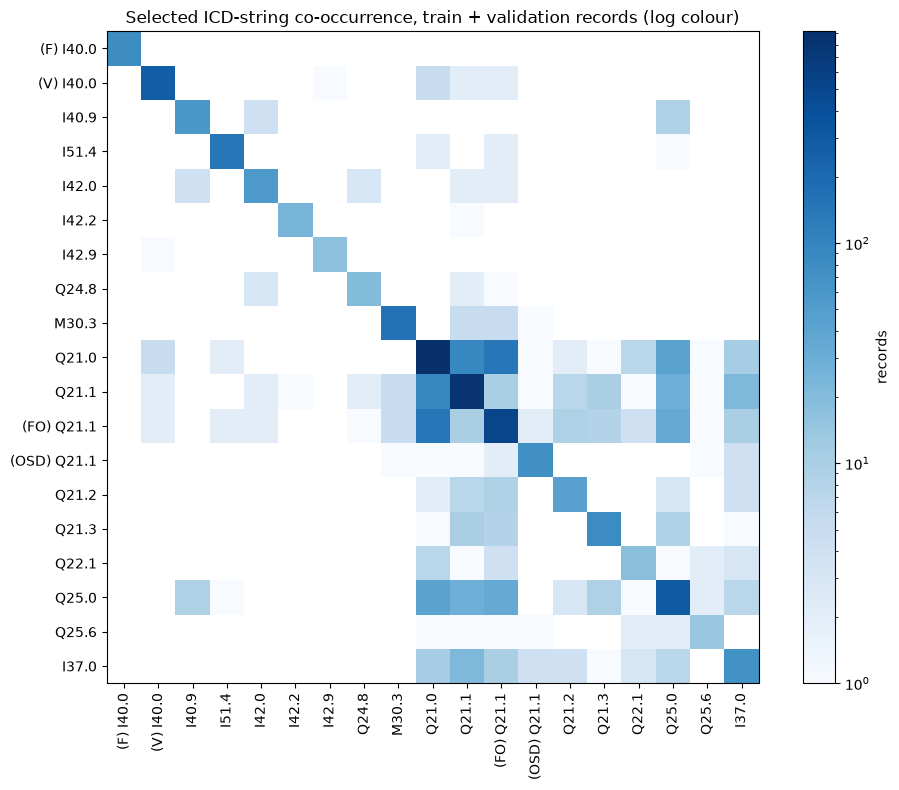

In [8]:
pairs=[]
for c1,c2 in itertools.combinations(selected_codes,2):
    sub=D[D.selected.map(lambda ss:c1 in ss and c2 in ss)]
    if len(sub):pairs.append({'code_1':c1,'code_2':c2,'records':len(sub),'patients':sub.patient_id.nunique()})
pairs=pd.DataFrame(pairs).sort_values('records',ascending=False)
pairs.to_csv(OUT/'observed_code_pairs.csv',index=False)
display(pairs.head(15))
mat=pd.DataFrame(0,index=selected_codes,columns=selected_codes,dtype=int)
for c in selected_codes:mat.loc[c,c]=int(D.selected.map(lambda ss:c in ss).sum())
for r in pairs.itertuples(index=False):mat.loc[r.code_1,r.code_2]=mat.loc[r.code_2,r.code_1]=r.records
mat.to_csv(OUT/'code_cooccurrence_matrix.csv')
fig,ax=plt.subplots(figsize=(10,8))
im=ax.imshow(mat.to_numpy(),cmap='Blues',norm=__import__('matplotlib').colors.LogNorm(vmin=1,vmax=max(2,int(mat.to_numpy().max()))))
ax.set_xticks(range(19),selected_codes,rotation=90);ax.set_yticks(range(19),selected_codes)
ax.set_title('Selected ICD-string co-occurrence, train + validation records (log colour)')
fig.colorbar(im,ax=ax,label='records');fig.tight_layout();fig.savefig(OUT/'code_cooccurrence.png',dpi=150);plt.show()

## Age and lead configuration by code

Age bins mirror the existing Week 6 age analysis. The table includes every code/split/age/lead combination, including zeros. `patients` is the number of unique patients represented in that particular stratum, so patients recorded at multiple ages or lead configurations may appear in multiple strata. `record_prevalence_in_stratum` uses all records in the same split/age/lead stratum as denominator.

In [9]:
strata=D.groupby(['split','age_group','lead_count'],observed=True).agg(stratum_records=('patient_id','size'),stratum_patients=('patient_id','nunique')).reset_index()
strata.to_csv(OUT/'age_lead_stratum_denominators.csv',index=False)
age_lead=[]
for split in ['train','validation']:
  for code in selected_codes:
    for age in D.age_group.cat.categories:
      for lead in [9,12]:
        g=D[(D.split==split)&(D.age_group==age)&(D.lead_count==lead)]
        sub=g.loc[g.selected.map(lambda ss:code in ss).to_numpy(dtype=bool)]
        age_lead.append({'split':split,'code':code,'age_group':str(age),'lead_count':lead,
                         'records':len(sub),'patients':sub.patient_id.nunique(),
                         'stratum_records':len(g),'stratum_patients':g.patient_id.nunique(),
                         'record_prevalence_in_stratum':len(sub)/len(g) if len(g) else np.nan})
age_lead=pd.DataFrame(age_lead)
age_lead.to_csv(OUT/'per_code_age_lead_by_split.csv',index=False)
display(strata)
display(age_lead.groupby(['code','age_group'],sort=False)[['records','patients']].sum().reset_index().pivot(index='code',columns='age_group',values='records').fillna(0).astype(int).reindex(selected_codes))
display(per_code.pivot(index='code',columns='split',values='nine_lead_records').reindex(selected_codes).astype(int))

,split,age_group,lead_count,stratum_records,stratum_patients
0,train,<2,9,885,675
1,train,<2,12,429,382
2,train,2–<6,9,375,322
3,train,2–<6,12,1813,1573
4,train,6–<12,9,38,34
5,train,6–<12,12,3633,3049
6,train,≥12,12,2770,2266
7,validation,<2,9,183,145
8,validation,<2,12,89,85
9,validation,2–<6,9,90,73


age_group,2–<6,6–<12,<2,≥12
code,,,,
(F) I40.0,14,41,0,25
(V) I40.0,72,101,28,72
I40.9,13,35,4,8
I51.4,36,67,15,23
I42.0,3,27,5,21
I42.2,3,6,5,10
I42.9,2,6,2,7
Q24.8,2,4,7,7
M30.3,86,24,48,1


split,train,validation
code,,
(F) I40.0,7,0
(V) I40.0,15,0
I40.9,1,0
I51.4,5,4
I42.0,3,2
I42.2,2,0
I42.9,0,0
Q24.8,5,3
M30.3,39,9


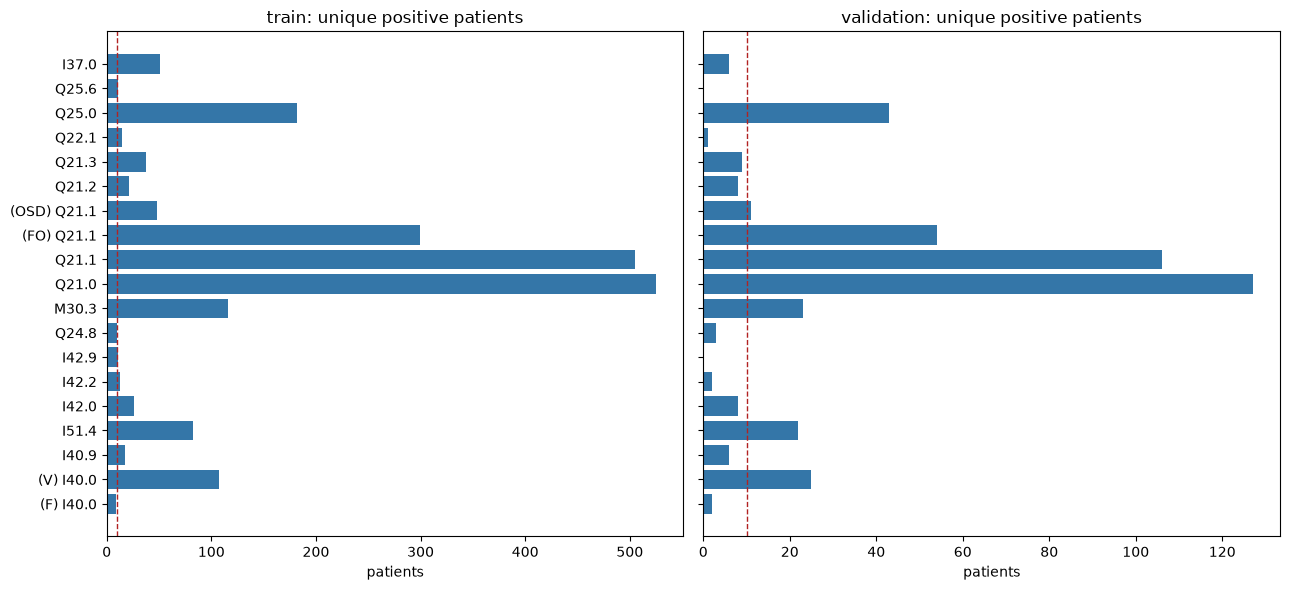

In [10]:
fig,axs=plt.subplots(1,2,figsize=(13,6),sharey=True)
for ax,split in zip(axs,['train','validation']):
    q=per_code[per_code.split==split].set_index('code').reindex(selected_codes)
    ax.barh(range(len(q)),q.patients,color='#3476a8')
    ax.set_yticks(range(len(q)),selected_codes);ax.invert_yaxis();ax.set_title(f'{split}: unique positive patients');ax.set_xlabel('patients')
    ax.axvline(10,color='firebrick',linestyle='--',linewidth=1)
fig.tight_layout();fig.savefig(OUT/'per_code_patient_counts.png',dpi=150);plt.show()

## Semantic audit and feasibility decision

**Observed:** all 19 exact strings occur in training, but `I42.9` and `Q25.6` have zero validation examples. Several other codes have fewer than ten validation patients (see table). Multiple selected strings occur on the same record. Local qualifiers `(F)`/`(V)` share ICD base `I40.0`; `Q21.1`, `(FO) Q21.1`, and `(OSD) Q21.1` share base `Q21.1`. The codebook also names `Q24.8` as noncompaction, while the ICD description is broader. Standard ICD definitions distinguish congenital pulmonary valve stenosis `Q22.1` from pulmonary valve stenosis `I37.0`; the local category text for `Q22.1` says right ventricular outflow tract stenosis. These are naming and ontology issues requiring a documented target policy, not automatic merges.

**Inference:** a multi-hot vector can represent the *observed selected strings* without contradicting the fact of co-occurrence. A 19-output model is technically definable, but a scientifically robust **19 independent disease detection** claim is not yet supported. Rare train/validation patient counts, absent validation classes, shared base codes, qualified local codes, and patient-linked labels undermine per-code validation and straightforward clinical interpretation. A sigmoid output per string would mean separate **code-presence predictions**, not statistical independence of diseases.

**Unresolved:** whether absent selected codes are true disease negatives; exact coding specificity/validity of local qualifiers; whether diagnoses were linked by admission versus patient across repeat ECGs; whether labels were active at the ECG time; whether rare code classes can be assessed with additional labels or adjudication. No external clinical ground truth is present here. The dataset paper states the medical record diagnoses were reviewed, but the available files do not permit an independent audit.

**Recommendation:** retain the binary experiments as historical results. Before modeling, define whether the objective is exact deposited code strings, ICD base codes, or clinically adjudicated phenotypes. For exact strings, treat any eventual model as exploratory, report per-code patient counts and uncertainty, and do not claim performance for codes absent or nearly absent in validation. Consider a clinically reviewed grouping only after its mapping is explicitly approved. Keep the held-out test set frozen; no test class audit or tuning is performed here.

**Paper discrepancy:** `Docs/ECG_Paper1.pdf` states **3,516** CVD ECG records in its abstract and acquisition step, but **3,716** in the disease-label section (with 10,474 other records). The current train/validation audit cannot adjudicate whole-dataset counts without test labels. This discrepancy should be checked against the source publication or depositor before using the paper's full-cohort figures.